In [15]:
from langchain_groq import ChatGroq
from langchain_huggingface import HuggingFaceEmbeddings
from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, BaseMessage
from langgraph.prebuilt import ToolNode, tools_condition
import os
from langchain_google_genai import GoogleGenerativeAIEmbeddings

# # Reads GROQ_API_KEY from your environment
# llm = ChatGroq(
#     model="llama-3.3-70b-versatile",
#     temperature=0
# )

# # Free local embeddings; no API key needed
# embeddings = HuggingFaceEmbeddings(
#     model_name="sentence-transformers/all-MiniLM-L6-v2"
# )

In [16]:
load_dotenv()

True

In [17]:
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    groq_api_key=os.getenv("GROQ_API_KEY"),
    temperature=0.7,
)

In [18]:
loader = PyPDFLoader("something.pdf")
docs = loader.load()

In [19]:
len(docs)

7

In [20]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
chunks = splitter.split_documents(docs)

In [21]:
len(chunks)

17

In [24]:
embeddings = GoogleGenerativeAIEmbeddings(
    model="gemini-embedding-001"
)
vector_store = FAISS.from_documents(chunks, embeddings)
vector_store.save_local("faiss_index")

In [25]:
vector_store

In [26]:
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k':4})

In [27]:
ans = retriever.invoke("What is the minor synopsis about?")
ans

[Document(id='734596d2-6f65-41b9-b53c-0d71c0ba83ed', metadata={'producer': 'Microsoft: Print To PDF', 'creator': 'PyPDF', 'creationdate': '2026-09-29T10:06:54+05:30', 'author': '', 'moddate': '2026-09-29T10:06:54+05:30', 'title': 'Microsoft Word - Multi-Agent_Student_Productivity_Assistant_Synopsis_01', 'source': 'something.pdf', 'total_pages': 7, 'page': 0, 'page_label': '1'}, page_content="1 \nTABLE OF CONTENT \nS.NO. TITLE PAGE NO. \n1. Introduction 2 \n2. Rationale 2 \n3. Objectives 3 \n4. Feasibility Study 3 \n5. Methodology/ Planning of Work 4 \n6. Software Required for the Project's Development 5 \n7. Expected Outcomes 6"),
 Document(id='503cb68f-e828-446d-bb80-1f4cb902f073', metadata={'producer': 'Microsoft: Print To PDF', 'creator': 'PyPDF', 'creationdate': '2026-09-29T10:06:54+05:30', 'author': '', 'moddate': '2026-09-29T10:06:54+05:30', 'title': 'Microsoft Word - Multi-Agent_Student_Productivity_Assistant_Synopsis_01', 'source': 'something.pdf', 'total_pages': 7, 'page': 6, 

In [28]:
@tool 
def rag_tool(query: str) -> str:
    """ 
    Retrieve relevant information from the PDF document.

    Use this tool when the user asks factual or conceptual questions that may be answered using the stored PDF documents. 

    Args: 
        query: The question or query used to retrieve PDF content
    """

    documents = retriever.invoke(query)

    if not documents:
        return "No relevant information was found in the PDF."

    formatted_documents = []

    for index, document in enumerate(documents, start=1):
        source = document.metadata.get("source", "Unknown source")
        page = document.metadata.get("page", "Unknown page")

        formatted_documents.append(
            f"Document: {index}\n"
            f"Source: {source}\n"
            f"Page: {page}\n"
            f"Content: {document.page_content}"
        )

    return "\n\n".join(formatted_documents)


In [29]:
tools = [rag_tool]
llm_with_tools = llm.bind_tools(tools)


In [30]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [31]:
# graph nodes
def chat_node(state: ChatState):
    """ LLM node that may answer or request a tool call."""
    messages = state['messages']
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

tool_node = ToolNode(tools) # Executes tool calls

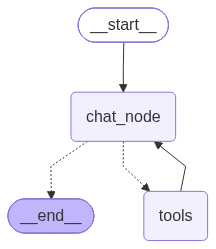

In [33]:
# graph structure
graph = StateGraph(ChatState)
graph.add_node("chat_node", chat_node)
graph.add_node("tools", tool_node)

graph.add_edge(START, "chat_node")

# If the LLM asked for a tool, go to ToolNode; else Finish
graph.add_conditional_edges("chat_node", tools_condition)

graph.add_edge("tools", "chat_node")
chatbot = graph.compile()

chatbot

In [34]:
# Regular chat
result = chatbot.invoke({"messages": [HumanMessage(content="Hello")]})

print(result["messages"][-1].content)

Hello! How can I help you today?


In [37]:
result = chatbot.invoke({"messages": [HumanMessage(content="Using the pdf notes, explain about the synopsis project.")]})



In [38]:
print(result["messages"][-1].content)

**Synopsis Project – “Multi‑Agent Student Productivity Assistant”**

The PDF you shared is a project synopsis for a student‑focused AI assistant.  It lays out the project’s purpose, design, and expected impact.  Below is a concise walkthrough of the key sections, distilled into a single narrative.

---

### 1. Introduction  
- **Goal**: Build an AI‑powered assistant that **automates email drafting** and **manages study schedules** for individual students.  
- **Problem**: Students often struggle with time‑management and feel hesitant to delegate tasks like email composition to an AI.  A single, integrated assistant can reduce friction, promote better habits, and free up time for learning.

### 2. Rationale  
- **User Need**: Students want quick, reliable email drafts and a clear view of upcoming study blocks.  
- **Current Gap**: Existing productivity tools are either too generic or require manual input for each task.  
- **Opportunity**: A **graph‑based multi‑agent system** can combin